In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import os
from google.colab import files

# Ensure dataset is loaded and df is defined
try:
    _ = df
except NameError:
    file_name = "data in m.xlsx"
    if not os.path.exists(file_name):
        print("Dataset file not found in storage. Please upload 'data in m.xlsx' below:")
        uploaded = files.upload()
        file_name = next(iter(uploaded))

    # Read the data fallback to first sheet if 'ARMPS 2010 Database' is missing
    try:
        df = pd.read_excel(file_name, sheet_name="ARMPS 2010 Database")
    except ValueError:
        df = pd.read_excel(file_name, sheet_name=0)

# Safely detect the vertical stress column
stress_col = None
possible_stress_names = ["Vertical Stress (MPa)", "Vertical Stress", "Stress"]

# 1. Look for exact matches
for name in possible_stress_names:
    if name in df.columns:
        stress_col = name
        break

# 2. Look for partial matches case-insensitively if not found
if stress_col is None:
    for col in df.columns:
        if "stress" in str(col).lower():
            stress_col = col
            break

if stress_col is None:
    print("Could not find a stress column in the dataset.")
    print("Available columns are:", list(df.columns))
else:
    print(f"Using column '{stress_col}' for Vertical Stress.")

    # Filter relevant columns and drop NaNs
    plot_data = df[["Depth of Cover (m)", stress_col]].dropna()

    plt.figure(figsize=(8, 5))
    plt.scatter(
        plot_data["Depth of Cover (m)"],
        plot_data[stress_col],
        alpha=0.6
    )

    plt.xlabel("Depth of Cover (m)")
    plt.ylabel(stress_col)
    plt.title(f"Depth of Cover vs. {stress_col}")

    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

    print("Correlation:",
          round(plot_data["Depth of Cover (m)"].corr(plot_data[stress_col]), 3))

Could not find a stress column in the dataset.
Available columns are: ['State', 'Mine', 'Mining Height1 (m)', 'Depth of Cover (m)', 'Entry Width (m)', 'Crosscut Spacing (m)', 'Crosscut Angle (degrees)', 'Number of Entries', 'ECTR(1)2 (m)', 'ECTR(2) (m)', 'ECTR(3) (m)', 'ECTR(4) (m)', 'ECTR(5) (m)', 'ECTR(6) (m)', 'ECTR(7) (m)', 'ECTR(8) (m)', 'ECTR(9) (m)', 'Loading Condition', 'Front Gob Extent (m)', '1st Side Gob Extent (m)', '2nd Side Gob Extent (m)', '1st Barrier Pillar Width (m)', '2nd Barrier Pillar Width (m)', '1st Slab Cut Depth (m)', '2nd Slab Cut Depth (m)', 'CMRR', 'Roof Strength Rating3', 'Thickness of Caprock (cm)', 'Region', 'Number of cases', 'Weight', 'w2', 'Seam Strength', 'Hardgrove Index (HGI)', 'Success4', 'FailType5', 'Sort']


The dataset used for this assignment is the ARMPS 2010 Database. Four numerical variables relevant to my research project on machine-learning-based prediction of roof falls are:

-Mining Height (m): The height of the mined excavation, measured in metres.

-Depth of Cover (m): The thickness of rock above the underground mine workings, measured in metres.

-Entry Width (m): The width of the underground mining entry, measured in metres.

-CMRR: The Coal Mine Roof Rating, which represents the geological and geotechnical characteristics of the coal mine roof.

These variables are relevant because mining geometry, depth of cover, and roof conditions can help describe the factors associated with underground roof stability.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files
uploaded = files.upload()

file_name = next(iter(uploaded))

df = pd.read_excel(
    file_name,
    sheet_name="ARMPS 2010 Database"
)

print("Dataset dimensions:", df.shape)
display(df.head())

Saving data in m.xlsx to data in m.xlsx
Dataset dimensions: (645, 37)


,State,Mine,Mining Height1 (m),Depth of Cover (m),Entry Width (m),Crosscut Spacing (m),Crosscut Angle (degrees),Number of Entries,ECTR(1)2 (m),ECTR(2) (m),...,Thickness of Caprock (cm),Region,Number of cases,Weight,w2,Seam Strength,Hardgrove Index (HGI),Success4,FailType5,Sort
0,AL,95,1.8288,350.520,6.096,30.480,90,5,26.8224,26.8224,...,0.0,AL,3.0,0.577350,230.0,1324,81.0,0,2.0,510
1,AL,95,1.8288,350.520,6.096,39.624,90,9,39.6240,39.6240,...,0.0,AL,3.0,0.577350,230.0,1324,81.0,1,1.0,511
2,AL,95,1.8288,350.520,6.096,27.432,90,10,27.4320,27.4320,...,0.0,AL,3.0,0.577350,230.0,1324,81.0,0,2.0,512
3,CO,17,3.5052,243.840,6.096,27.432,90,10,25.9080,25.9080,...,0.0,CO,2.0,0.707107,282.0,2632,46.3,1,1.0,76
4,CO,18,2.7432,475.488,6.096,21.336,90,6,39.6240,39.6240,...,0.0,CO,2.0,0.707107,282.0,2632,46.3,0,4.0,77


In [5]:
import pandas as pd
import numpy as np

# Load the ARMPS dataset
df = pd.read_excel(
    "data in m.xlsx",
    sheet_name="ARMPS 2010 Database"
)

# Select four numerical variables
variables = [
    "Depth of Cover (m)",
    "Mining Height1 (m)",
    "Entry Width (m)",
    "CMRR"
]

# Calculate descriptive statistics
summary = pd.DataFrame({
    "Count": df[variables].count(),
    "Mean": df[variables].mean(),
    "Median": df[variables].median(),
    "Minimum": df[variables].min(),
    "Maximum": df[variables].max(),
    "Range": df[variables].max() - df[variables].min(),
    "Variance": df[variables].var(),
    "Standard Deviation": df[variables].std()
})

display(summary.round(3))


,Count,Mean,Median,Minimum,Maximum,Range,Variance,Standard Deviation
Depth of Cover (m),645,271.751,268.834,44.196,670.560,626.364,17663.579,132.904
Mining Height1 (m),645,1.927,1.829,0.762,5.334,4.572,0.443,0.666
Entry Width (m),645,5.993,6.096,2.743,11.125,8.382,0.112,0.335
CMRR,612,32.351,44.000,2.000,92.000,90.000,759.295,27.555



The descriptive statistics show that the ARMPS dataset contains different mining conditions and roof-quality ratings.

The mean depth of cover is approximately 271.75 m, with a standard deviation of 132.90 m. This indicates considerable variation in the depth of cover across the records. The mean mining height is approximately 1.93 m, while the mean entry width is approximately 5.99 m.

For CMRR, the mean is 32.35, while the median is 44.00. The difference suggests that some low CMRR values may be pulling the mean downward. The standard deviation of 27.56 also indicates substantial variation in roof-quality ratings.

Overall, these statistics help describe the distribution and variability of the selected variables. Understanding this variability is important when preparing data for machine learning because the selected parameters represent different mining conditions that may be relevant to roof stability.

Covariance and Correlation

In this section, I examine the relationship between Depth of Cover and Coal Mine Roof Rating (CMRR) using covariance and correlation. Covariance indicates whether two variables tend to increase or decrease together, while correlation measures the strength and direction of their linear relationship on a scale from -1 to +1.

In [6]:
import pandas as pd

# Select the two variables
depth = df["Depth of Cover (m)"]
cmrr = df["CMRR"]

# Combine variables and remove rows with missing values
data = pd.DataFrame({
    "Depth of Cover (m)": depth,
    "CMRR": cmrr
}).dropna()

# Calculate covariance
covariance = data["Depth of Cover (m)"].cov(data["CMRR"])

# Calculate Pearson correlation
correlation = data["Depth of Cover (m)"].corr(data["CMRR"])

print("Number of observations:", len(data))
print("Covariance:", round(covariance, 3))
print("Correlation:", round(correlation, 3))


Number of observations: 612
Covariance: -1405.887
Correlation: -0.384


### Interpretation of Covariance and Correlation

The covariance between Depth of Cover and CMRR is approximately -1405.887, indicating an inverse tendency between the two variables. The Pearson correlation coefficient is approximately -0.384, showing a moderate negative linear relationship.

This means that records with greater depth of cover tend to have lower CMRR values, but the association is not strong enough to predict CMRR accurately from depth alone. Other geological and mining conditions may also influence roof quality.

Correlation does not necessarily imply causation. These results show an association between two variables, but they do not prove that depth of cover causes changes in CMRR. Further investigation and additional variables would be required to understand the factors associated with roof stability and roof falls.

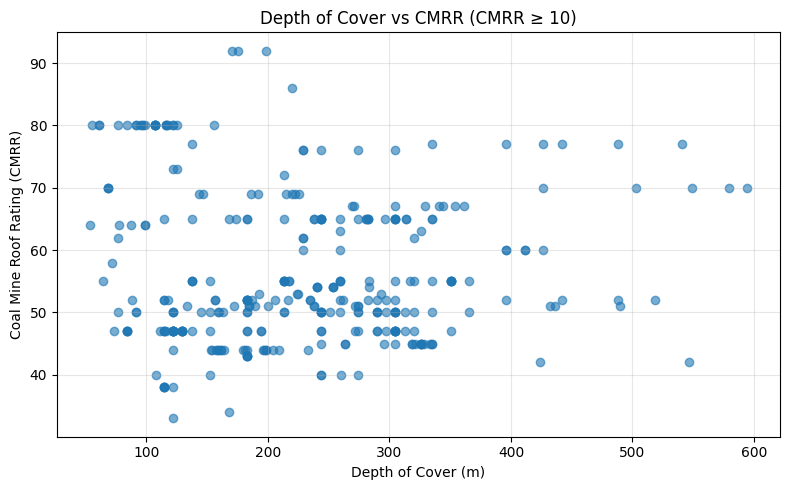

Records plotted: 330
Single-digit CMRR values excluded: 282


In [5]:

import matplotlib.pyplot as plt

# Keep records with CMRR of 10 or greater
plot_data = df[
    (df["CMRR"] >= 10) &
    (df["Depth of Cover (m)"].notna())
].copy()

# Create the scatter plot
plt.figure(figsize=(8, 5))

plt.scatter(
    plot_data["Depth of Cover (m)"],
    plot_data["CMRR"],
    alpha=0.6
)

plt.xlabel("Depth of Cover (m)")
plt.ylabel("Coal Mine Roof Rating (CMRR)")
plt.title("Depth of Cover vs CMRR (CMRR ≥ 10)")

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("Records plotted:", len(plot_data))
print("Single-digit CMRR values excluded:",
      (df["CMRR"] < 10).sum())


Interpretation of the Scatter Plot

The scatter plot shows the relationship between Depth of Cover and Coal Mine Roof Rating (CMRR). The points are expected to display a general downward tendency, which is consistent with the negative correlation coefficient of approximately -0.384.

However, the points are scattered rather than following a perfect straight line. This indicates that depth of cover alone does not fully explain variations in CMRR. Other geological and geotechnical factors may also be relevant to roof stability.The plot shows an association between the two variables, but it does not establish a cause-and-effect relationship.

### a. What do the statistics tell you about your data?

The descriptive statistics show that the mean Depth of Cover is approximately 271.75 m, with a median of 268.83 m and a standard deviation of 132.90 m. This indicates considerable variation in the depth of cover across the dataset. For CMRR, the mean is approximately 32.35, while the median is 44.00, suggesting that some low CMRR values may be pulling the mean downward. The standard deviation of 27.56 also indicates substantial variation in roof-quality ratings. These statistics help describe the distribution of mining conditions and roof quality in the ARMPS dataset.

### b. What does the correlation tell you about the relationship between the two variables?

The Pearson correlation coefficient between Depth of Cover and CMRR is approximately −0.384, indicating a moderate negative linear relationship. This means that records with greater depth of cover tend to be associated with lower CMRR values, although there are exceptions. The relationship is not strong enough to explain CMRR accurately using depth of cover alone. Other geological and geotechnical factors may also influence roof quality.

### c. Does correlation necessarily mean that one variable causes the other?

No, correlation does not necessarily imply causation. Although the dataset shows a negative association between Depth of Cover and CMRR, this does not prove that greater depth directly causes lower roof-quality ratings. CMRR reflects roof-rock characteristics, while depth of cover represents the thickness of overlying rock. Other factors, such as rock type, discontinuities, moisture conditions and geological structures, may affect roof quality and stability. Further investigation would be required to establish causal relationships.

### Input → Function/Model → Output

**Input (X):** Entry Width (m)

**Function/Model (f):** A mathematical function or machine learning model.

**Output (Y):** Predicted Mining Height (m).

The relationship can be expressed as:

\[
\hat{Y}=f(X)
\]

Or, using the selected variables:

\[
\widehat{\text{Mining Height}}=f(\text{Entry Width})
\]

**In simple terms:** The entry width is supplied to a model, which uses the relationship learned from the dataset to estimate the mining height.

**Input → Model → Output**

Entry Width → Mathematical/ML Model → Predicted Mining Height

Input (X)
Entry Width = 6.0 m

Function (f)
\(f(X)=0.3X+0.1\)

Output (\(\hat{Y}\))
Predicted Mining Height = 1.9 m

In [6]:
def predict_mining_height(entry_width):
    """
    Input: Entry Width (m)
    Output: Predicted Mining Height (m)
    """
    predicted_height = 0.3 * entry_width + 0.1
    return predicted_height

In [7]:
entry_width = 6.0  # Entry Width in metres

predicted_height = predict_mining_height(entry_width)

print("Entry Width:", entry_width, "m")
print("Predicted Mining Height:", predicted_height, "m")

Entry Width: 6.0 m
Predicted Mining Height: 1.9 m
